
# Step 7. Genetic Analysis — Genotype QC and GWAS

## 1. Overview

This notebook demonstrates the genotype quality control (QC) and genetic association analysis workflow using chromosome 22 genotype data from 100 demonstration participants.

The demonstration reproduces the computational steps of:

1. Genotype and phenotype verification.
2. Sample-level genotype missingness filtering.
3. SNP-level missingness, minor allele frequency (MAF), and Hardy–Weinberg equilibrium (HWE) filtering.
4. LD pruning and illustrative principal component analysis (PCA).
5. Type 2 diabetes (T2D) association analysis using PLINK 2.0.
6. LD-based clumping.
7. Association and quantile–quantile (QQ) plots.

The demonstration is intended to reproduce the computational workflow rather than the association findings of the original study.

## 2. Original Study

The original study started with 131,048 participants and 9,814,944 imputed variants.

### Sample Quality Control

The following procedures were performed:

| QC step | Exclusion criterion |
|---|---|
| Sex consistency | Discrepancy between self-reported and genetically inferred sex |
| Sample missingness | Missing genotype rate > 5% |
| Homozygosity | Outside mean ± 5 SD |
| Relatedness | Kinship coefficient > 0.0884 |
| Ancestry | Divergent ancestry |

After sample-level QC, 108,251 participants remained.

### SNP Quality Control

| QC step | Threshold |
|---|---|
| Variant missingness | ≤ 0.05 |
| Minor allele frequency | ≥ 0.005 |
| Hardy–Weinberg equilibrium | P ≥ 1 × 10^-6 |

After SNP-level QC, 4,233,180 variants remained.

### Association Analyses

The original study performed:

- Logistic GWAS for T2D.
- Linear GWAS for fasting glucose.
- Linear GWAS for HbA1c.
- Genetic association analyses for 13 abdominal ultrasound and 24 DXA/BMD image-derived phenotypes (IDPs).

Age, sex, family history, and genome-wide PC1–PC10 were included as covariates.

## 3. GitHub Demonstration

The demonstration uses only chromosome 22 and 100 participants.

| Component | Original study | Demonstration |
|---|---|---|
| Genotype | Genome-wide imputed genotype | Chromosome 22 |
| Participants | 108,251 after QC | 100 before QC |
| Sample QC | Complete sample QC | Genotype missingness |
| SNP QC | Missingness, MAF, HWE | Same numerical thresholds |
| PCA | Genome-wide | Chromosome 22 illustration |
| Phenotype | T2D | Existing T2D column |
| Association | Logistic regression | Logistic regression with Firth fallback |
| Covariates | AGE, SEX, family history, PC1–PC10 | AGE, SEX, family history, optional PC1–PC2 |

Sex consistency, homozygosity outlier removal, relatedness removal, and ancestry exclusion are not reproduced as genome-wide QC procedures in this demonstration.

PCA computed from chromosome 22 is illustrative and should not be interpreted as an accurate ancestry estimate.

The existing `T2D` phenotype is used without modification.

No disease phenotypes are simulated.

## 4. Multiple-testing Correction

The original study estimated:

- Effective independent variant tests: 768,377.22.
- Effective independent phenotype tests: 25.
- Study-wide significance threshold: approximately 2.6 × 10^-9.

LD clumping settings:

| Parameter | Value |
|---|---|
| clump-p1 | 1e-4 |
| clump-p2 | 1e-2 |
| clump-r2 | 0.1 |
| clump-kb | 250 |

The clumping index-variant threshold is not the study-wide significance threshold.

In this demonstration, the same clumping settings are applied to the QC-passed chromosome 22 genotype, which serves as the LD reference.

## 5. Limitations

The small sample size and restriction to chromosome 22 substantially limit association power.

GWAS results from this demonstration must not be interpreted as newly discovered significant genetic loci.

Fasting glucose, HbA1c, and the 37 original IDPs are not included in the current demonstration dataset; their association analyses are documented but not executed.

The demonstration retains summary statistics and top-ranked variants even when no association reaches the study-wide significance threshold.

## 6. Outputs

All files are written to:

`Outputs/Step7_GWAS/`

The original genotype input files are never modified.



## Environment Setup

This notebook uses the same PLINK2 executable-location convention as `1.Step1_PRS_Construction.ipynb`.

### Kernel

Select the `T2D Main` Jupyter Kernel corresponding to the environment defined in:

`environments/main.yml`

The notebook locates PLINK2 using:

```python
PLINK2 = Path(sys.prefix) / "bin/plink2"
```

This ensures that PLINK2 comes from the active Jupyter environment, without depending on a server-specific executable path.

### Install the Environment

From the repository root:

```bash
conda env create -f environments/main.yml
```

If the existing environment is missing PLINK2:

```bash
conda install -n t2d-main \
    -c conda-forge -c bioconda \
    plink2=2.0.0a.7.8 -y
```

### Input Files

- `Demo_data/1-3.Sample_genotype/demo_chr22.bed`
- `Demo_data/1-3.Sample_genotype/demo_chr22.bim`
- `Demo_data/1-3.Sample_genotype/demo_chr22.fam`
- `Demo_data/1-1.Sample_information/sample_information.csv`

The alternative repository directory name `1.Demo_data` is also supported.

The PLINK FAM individual IDs must match the `Demo_ID` identifiers, or a verified mapping file must be provided.

The notebook uses Python to execute PLINK2 as a subprocess. No shell commands are required inside the analysis cells.

All analysis is CPU-based.


In [1]:
# ============================================================
# 0. GWAS — Configuration
# Kernel: T2D Main
# ============================================================

from pathlib import Path
import sys
import subprocess
import shlex

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display


# ============================================================
# 0.1 Project and Input Paths
# ============================================================

PROJECT_ROOT = Path.cwd().resolve()

# Match Step 1 naming first; support 1.Demo_data too.
DATA_CANDIDATES = [
    PROJECT_ROOT / "Demo_data",
]

DATA_DIR = next(
    (p for p in DATA_CANDIDATES if p.is_dir()),
    None
)

if DATA_DIR is None:
    raise FileNotFoundError(
        "Neither Demo_data nor 1.Demo_data was found "
        "under the current working directory."
    )

GENOTYPE_PREFIX = (
    DATA_DIR
    / "1-3.Sample_genotype"
    / "demo_chr22"
)

SAMPLE_FILE = (
    DATA_DIR
    / "1-1.Sample_information"
    / "sample_information.csv"
)

MAPPING_FILE = (
    DATA_DIR
    / "1-1.Sample_information"
    / "genotype_id_mapping.csv"
)

OUTPUT_DIR = PROJECT_ROOT / "Outputs" / "Step7_GWAS"
QC_DIR = OUTPUT_DIR / "QC"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
QC_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 0.2 PLINK2 — Same Convention as Step 1
# ============================================================

PLINK2 = Path(sys.prefix) / "bin" / "plink2"

print("Python executable:", sys.executable)
print("Python environment:", sys.prefix)
print("Expected PLINK2:", PLINK2)

if not PLINK2.is_file():
    raise FileNotFoundError(
        "PLINK2 was not found in the current Kernel.\n"
        f"Expected location: {PLINK2}\n"
        "Please select T2D Main and ensure that "
        "PLINK2 is installed in that environment."
    )


# ============================================================
# 0.3 Parameters
# ============================================================

THREADS = 4

# Sample QC
MIND = 0.05

# SNP QC
GENO = 0.05
MAF = 0.005
HWE = 1e-6

# Illustrative PCA
RUN_PCA = True
N_PCS = 2
PRUNE_WINDOW = "200kb"
PRUNE_R2 = 0.2

# Whether to include the available illustrative PCs
ADJUST_PCS = True

# Association
GLM_METHOD = "firth-fallback"

# Study-wide threshold from the original study
STUDY_WIDE_P = 2.6e-9

# Clumping from the original study
CLUMP_P1 = 1e-4
CLUMP_P2 = 1e-2
CLUMP_R2 = 0.1
CLUMP_KB = 250


# ============================================================
# 0.4 Helper: Execute PLINK2
# ============================================================

def run_plink(*arguments):

    command = [
        str(PLINK2),
        *[str(arg) for arg in arguments]
    ]

    print("\n$", shlex.join(command))

    result = subprocess.run(
        command,
        capture_output=True,
        text=True
    )

    if result.returncode != 0:

        print("\nPLINK2 STDOUT:")
        print(result.stdout[-4000:])

        print("\nPLINK2 STDERR:")
        print(result.stderr[-4000:])

        raise RuntimeError(
            f"PLINK2 failed (exit code {result.returncode})."
        )

    output_lines = result.stdout.splitlines()
    print("\n".join(output_lines[-12:]))

    return result


# ============================================================
# 0.5 Helper: Count Genotype Samples / Variants
# ============================================================

def count_bfile(prefix):

    fam_file = Path(f"{prefix}.fam")
    bim_file = Path(f"{prefix}.bim")

    assert fam_file.is_file(), fam_file
    assert bim_file.is_file(), bim_file

    with fam_file.open() as f:
        n_samples = sum(
            bool(line.strip())
            for line in f
        )

    with bim_file.open() as f:
        n_variants = sum(
            bool(line.strip())
            for line in f
        )

    return n_samples, n_variants


# ============================================================
# 0.6 Verify Input Files and PLINK2
# ============================================================

for extension in [".bed", ".bim", ".fam"]:
    file = Path(str(GENOTYPE_PREFIX) + extension)
    assert file.is_file(), file

assert SAMPLE_FILE.is_file(), SAMPLE_FILE

run_plink("--version")

N_INITIAL, M_INITIAL = count_bfile(
    GENOTYPE_PREFIX
)

assert N_INITIAL == 100
assert M_INITIAL > 0

print("\n" + "=" * 65)
print("GWAS CONFIGURATION READY")
print("=" * 65)

print("Genotype prefix:", GENOTYPE_PREFIX)
print("Initial samples:", N_INITIAL)
print("Initial variants:", M_INITIAL)

print("Sample missingness:", MIND)
print("Variant missingness:", GENO)
print("MAF:", MAF)
print("HWE:", HWE)

print("PCA:", RUN_PCA)
print("Association:", GLM_METHOD)
print("Study-wide P:", STUDY_WIDE_P)

Python executable: [LOCAL_PATH]
Python environment: [LOCAL_PATH]
Expected PLINK2: [LOCAL_PATH]

$ [LOCAL_PATH] --version
PLINK v2.0.0-a.7.13 64-bit (15 Oct 2026)

GWAS CONFIGURATION READY
Genotype prefix: [LOCAL_PATH]
Initial samples: 100
Initial variants: 1000
Sample missingness: 0.05
Variant missingness: 0.05
MAF: 0.005
HWE: 1e-06
PCA: True
Association: firth-fallback
Study-wide P: 2.6e-09


In [2]:
# ============================================================
# 1. Verify Genotype and Phenotype Matching
# ============================================================

# ============================================================
# 1.1 Read FAM / BIM / Sample Information
# ============================================================

fam = pd.read_csv(
    f"{GENOTYPE_PREFIX}.fam",
    sep=r"\s+",
    header=None,
    dtype=str,
    names=[
        "FID", "IID", "Father",
        "Mother", "SEX_FAM", "PHENO_FAM"
    ]
)

bim = pd.read_csv(
    f"{GENOTYPE_PREFIX}.bim",
    sep=r"\s+",
    header=None,
    dtype=str,
    names=[
        "CHR", "ID", "CM",
        "POS", "A1", "A2"
    ]
)

sample_info = pd.read_csv(
    SAMPLE_FILE,
    dtype={"Demo_ID": str}
)

REQUIRED_COLUMNS = [
    "Demo_ID",
    "T2D",
    "AGE",
    "SEX",
    "Familyall_numeric",
]

missing = (
    set(REQUIRED_COLUMNS)
    - set(sample_info.columns)
)

assert not missing, f"Missing columns: {missing}"

assert len(fam) == 100
assert len(sample_info) == 100
assert sample_info["Demo_ID"].is_unique
assert not fam[["FID", "IID"]].duplicated().any()

assert set(bim["CHR"]) == {"22"}


# ============================================================
# 1.2 Match FAM IDs with Demo_ID
# ============================================================

direct_match = (
    fam["IID"].is_unique
    and set(fam["IID"]) == set(sample_info["Demo_ID"])
)

if direct_match:

    id_map = fam[
        ["FID", "IID"]
    ].copy()

    id_map["Demo_ID"] = id_map["IID"]

    print("Genotype IID matches Demo_ID directly.")

else:

    if not MAPPING_FILE.is_file():
        raise FileNotFoundError(
            "Genotype IID does not match Demo_ID, "
            "and no mapping file was found:\n"
            f"{MAPPING_FILE}\n"
            "Prepare a verified Demo_ID/FID/IID mapping "
            "from the original data-preparation step."
        )

    id_map = pd.read_csv(
        MAPPING_FILE,
        dtype=str
    )

    assert {
        "Demo_ID", "FID", "IID"
    }.issubset(id_map.columns)

    id_map = id_map[
        ["Demo_ID", "FID", "IID"]
    ].copy()

    assert id_map["Demo_ID"].is_unique
    assert not id_map[["FID", "IID"]].duplicated().any()

    assert set(
        map(tuple, id_map[["FID", "IID"]].to_numpy())
    ) == set(
        map(tuple, fam[["FID", "IID"]].to_numpy())
    )

    print("Using verified genotype ID mapping.")


# ============================================================
# 1.3 Merge Participant Information
# ============================================================

samples = id_map.merge(
    sample_info[REQUIRED_COLUMNS],
    on="Demo_ID",
    how="left",
    validate="one_to_one"
)

assert len(samples) == 100
assert samples[REQUIRED_COLUMNS].notna().all().all()

for col in [
    "T2D",
    "AGE",
    "SEX",
    "Familyall_numeric"
]:

    samples[col] = pd.to_numeric(
        samples[col],
        errors="raise"
    )

assert np.isfinite(
    samples[
        ["T2D", "AGE", "SEX", "Familyall_numeric"]
    ].to_numpy(dtype=float)
).all()

assert samples["T2D"].isin([0, 1]).all()


# ============================================================
# 1.4 Convert T2D for PLINK2
# ============================================================

# Original Demo:
#   T2D = 0 -> Control
#   T2D = 1 -> Case
#
# PLINK binary phenotype:
#   1 = Control
#   2 = Case

samples["T2D_PLINK"] = (
    samples["T2D"] + 1
).astype(int)

samples["SEX_numeric"] = (
    samples["SEX"].astype(float)
)

# This maintains the supplied numeric SEX coding.
# PLINK will use it as a binary numeric covariate.


# ============================================================
# 1.5 Verification
# ============================================================

assert set(
    map(tuple, samples[["FID", "IID"]].to_numpy())
) == set(
    map(tuple, fam[["FID", "IID"]].to_numpy())
)

print("=" * 65)
print("GENOTYPE AND PHENOTYPE MATCHING")
print("=" * 65)

print("Genotype samples:", len(fam))
print("Matched samples:", len(samples))

print("T2D cases:", int((samples["T2D"] == 1).sum()))
print("Controls:", int((samples["T2D"] == 0).sum()))

print("\nSample preview:")

display(
    samples[
        [
            "Demo_ID",
            "FID",
            "IID",
            "T2D",
            "T2D_PLINK",
            "AGE",
            "SEX_numeric",
            "Familyall_numeric"
        ]
    ].head(10)
)

Genotype IID matches Demo_ID directly.
GENOTYPE AND PHENOTYPE MATCHING
Genotype samples: 100
Matched samples: 100
T2D cases: 50
Controls: 50

Sample preview:


,Demo_ID,FID,IID,T2D,T2D_PLINK,AGE,SEX_numeric,Familyall_numeric
0,D001,D001,D001,0,1,65,2.0,0
1,D002,D002,D002,0,1,75,1.0,0
2,D003,D003,D003,1,2,54,2.0,0
3,D004,D004,D004,1,2,61,1.0,0
4,D005,D005,D005,1,2,73,1.0,0
5,D006,D006,D006,1,2,72,1.0,0
6,D007,D007,D007,0,1,74,1.0,1
7,D008,D008,D008,1,2,48,2.0,0
8,D009,D009,D009,1,2,70,2.0,1
9,D010,D010,D010,0,1,54,1.0,0


In [3]:
# ============================================================
# 2. Genotype Quality Control
# ============================================================

QC_RECORDS = []


# ============================================================
# 2.1 Record Counts
# ============================================================

def record_qc(stage, prefix):

    n, m = count_bfile(prefix)

    if n == 0 or m == 0:
        raise RuntimeError(
            f"No genotype data remain after {stage}."
        )

    QC_RECORDS.append({
        "Stage": stage,
        "N_Samples": n,
        "N_Variants": m,
    })

    print(
        f"{stage}: "
        f"{n:,} samples, {m:,} SNPs"
    )


# ============================================================
# 2.2 Original Genotype
# ============================================================

record_qc(
    "00_Raw",
    GENOTYPE_PREFIX
)

# Generate raw missingness reports
run_plink(
    "--bfile", GENOTYPE_PREFIX,
    "--missing",
    "--threads", THREADS,
    "--out", QC_DIR / "00_Raw_Missingness"
)


# ============================================================
# 2.3 Sample Missingness
# ============================================================

QC_SAMPLE = QC_DIR / "01_SampleMissingness"

run_plink(
    "--bfile", GENOTYPE_PREFIX,
    "--mind", MIND,
    "--make-bed",
    "--threads", THREADS,
    "--out", QC_SAMPLE
)

record_qc(
    "01_SampleMissingness",
    QC_SAMPLE
)


# ============================================================
# 2.4 SNP Missingness
# ============================================================

QC_GENO = QC_DIR / "02_VariantMissingness"

run_plink(
    "--bfile", QC_SAMPLE,
    "--geno", GENO,
    "--make-bed",
    "--threads", THREADS,
    "--out", QC_GENO
)

record_qc(
    "02_VariantMissingness",
    QC_GENO
)


# ============================================================
# 2.5 Minor Allele Frequency
# ============================================================

QC_MAF = QC_DIR / "03_MAF"

run_plink(
    "--bfile", QC_GENO,
    "--maf", MAF,
    "--make-bed",
    "--threads", THREADS,
    "--out", QC_MAF
)

record_qc(
    "03_MAF",
    QC_MAF
)


# ============================================================
# 2.6 Hardy-Weinberg Equilibrium
# ============================================================

QC_FINAL = QC_DIR / "04_Final_QC"

run_plink(
    "--bfile", QC_MAF,
    "--hwe", HWE,
    "--make-bed",
    "--threads", THREADS,
    "--out", QC_FINAL
)

record_qc(
    "04_Final_QC",
    QC_FINAL
)


# ============================================================
# 2.7 Construct QC Summary
# ============================================================

qc_summary = pd.DataFrame(
    QC_RECORDS
)

qc_summary["Removed_Samples"] = (
    qc_summary["N_Samples"].shift(1)
    - qc_summary["N_Samples"]
).fillna(0).astype(int)

qc_summary["Removed_Variants"] = (
    qc_summary["N_Variants"].shift(1)
    - qc_summary["N_Variants"]
).fillna(0).astype(int)


# ============================================================
# 2.8 Save Summary
# ============================================================

QC_SUMMARY_FILE = (
    OUTPUT_DIR / "QC_Summary.csv"
)

qc_summary.to_csv(
    QC_SUMMARY_FILE,
    index=False
)

print("\n" + "=" * 65)
print("GENOTYPE QC SUMMARY")
print("=" * 65)

display(qc_summary)

print(
    "\nFinal QC genotype:",
    QC_FINAL
)

00_Raw: 100 samples, 1,000 SNPs

$ [LOCAL_PATH] --bfile [LOCAL_PATH] --missing --threads 4 --out [LOCAL_PATH]
[LOCAL_PATH]
1 binary phenotype loaded (50 cases, 50 controls).
Calculating sample missingness rates... done.
Calculating allele frequencies... done.
--missing: Sample missing data report written to
[LOCAL_PATH]
.
--missing variant report: 99%
--missing: Variant missing data report written to
[LOCAL_PATH]
.
End time: Tue Nov  3 12:39:16 2026

$ [LOCAL_PATH] --bfile [LOCAL_PATH] --mind 0.05 --make-bed --threads 4 --out [LOCAL_PATH]
100 samples (54 females, 46 males; 100 founders) remaining after main filters.
50 cases and 50 controls remaining after main filters.
Writing
[LOCAL_PATH]
... done.
Writing
[LOCAL_PATH]
... done.
Writing
[LOCAL_PATH]
... done.
End time: Tue Nov  3 12:39:16 2026
01_SampleMissingness: 100 samples, 1,000 SNPs

$ [LOCAL_PATH] --bfile [LOCAL_PATH] --geno 0.05 --make-bed --threads 4 --out [LOCAL_PATH]
--geno: 0 variants removed due to missing genotype data.

,Stage,N_Samples,N_Variants,Removed_Samples,Removed_Variants
0,00_Raw,100,1000,0,0
1,01_SampleMissingness,100,1000,0,0
2,02_VariantMissingness,100,1000,0,0
3,03_MAF,100,1000,0,0
4,04_Final_QC,100,1000,0,0



Final QC genotype: [LOCAL_PATH]



$ [LOCAL_PATH] --bfile [LOCAL_PATH] --indep-pairwise 200kb 0.2 --threads 4 --out [LOCAL_PATH]
1000 variants loaded from
[LOCAL_PATH]
1 binary phenotype loaded (50 cases, 50 controls).
Calculating allele frequencies... done.
--indep-pairwise (3 compute threads): 0/1000 variants removed.
Writing...
Variant lists written to
[LOCAL_PATH]
and
[LOCAL_PATH]
.
End time: Tue Nov  3 12:39:22 2026

LD-independent SNPs: 1000

$ [LOCAL_PATH] --bfile [LOCAL_PATH] --extract [LOCAL_PATH] --pca 2 --threads 4 --out [LOCAL_PATH]
1 binary phenotype loaded (50 cases, 50 controls).
--extract: 1000 variants remaining.
Calculating allele frequencies... done.
1000 variants remaining after main filters.
Constructing GRM: done.
Extracting eigenvalues and eigenvectors... done.
--pca: Eigenvectors written to
[LOCAL_PATH]
, and eigenvalues written to
[LOCAL_PATH]
.
End time: Tue Nov  3 12:39:22 2026

PCA completed:


,FID,IID,PC1,PC2
0,D001,D001,-0.144486,-0.054277
1,D002,D002,0.116654,-0.038370
2,D003,D003,0.075186,0.176250
3,D004,D004,-0.073950,-0.133349
4,D005,D005,-0.013334,-0.034834


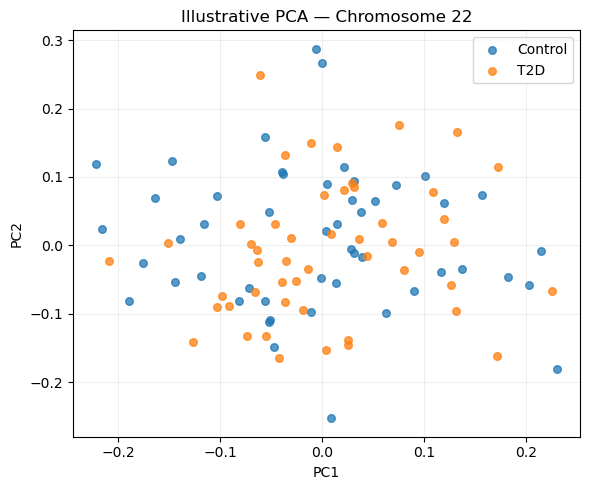


PCA step completed.


In [4]:
# ============================================================
# 3. LD Pruning and Illustrative PCA
# ============================================================

PRUNE_PREFIX = OUTPUT_DIR / "Demo_LD_Prune"
PCA_PREFIX = OUTPUT_DIR / "Demo_PCA"

pca_df = None
PC_COLUMNS = []


# ============================================================
# 3.1 LD Pruning
# ============================================================

if RUN_PCA:

    run_plink(
        "--bfile", QC_FINAL,
        "--indep-pairwise",
        PRUNE_WINDOW,
        PRUNE_R2,
        "--threads", THREADS,
        "--out", PRUNE_PREFIX
    )

    PRUNE_FILE = Path(
        f"{PRUNE_PREFIX}.prune.in"
    )

    assert PRUNE_FILE.is_file(), PRUNE_FILE

    prune_ids = [
        line.strip()
        for line in PRUNE_FILE.read_text().splitlines()
        if line.strip()
    ]

    print(
        "\nLD-independent SNPs:",
        len(prune_ids)
    )


    # ========================================================
    # 3.2 PCA
    # ========================================================

    if len(prune_ids) >= max(10, N_PCS + 1):

        run_plink(
            "--bfile", QC_FINAL,
            "--extract", PRUNE_FILE,
            "--pca", N_PCS,
            "--threads", THREADS,
            "--out", PCA_PREFIX
        )

        PCA_FILE = Path(
            f"{PCA_PREFIX}.eigenvec"
        )

        pca_df = pd.read_csv(
            PCA_FILE,
            sep=r"\s+",
            dtype=str
        )

        pca_df.columns = (
            pca_df.columns.str.lstrip("#")
        )

        PC_COLUMNS = [
            f"PC{i}"
            for i in range(1, N_PCS + 1)
        ]

        assert set(
            ["FID", "IID", *PC_COLUMNS]
        ).issubset(pca_df.columns)

        assert not pca_df[
            ["FID", "IID"]
        ].duplicated().any()

        for col in PC_COLUMNS:
            pca_df[col] = pd.to_numeric(
                pca_df[col],
                errors="raise"
            )

        assert np.isfinite(
            pca_df[PC_COLUMNS].to_numpy(dtype=float)
        ).all()

        print("\nPCA completed:")
        display(pca_df.head())

    else:

        print(
            "Insufficient LD-independent SNPs. "
            "Skipping PCA."
        )


# ============================================================
# 3.3 Plot PC1 versus PC2
# ============================================================

if pca_df is not None and len(PC_COLUMNS) >= 2:

    pca_plot = pca_df.merge(
        samples[
            ["FID", "IID", "T2D"]
        ],
        on=["FID", "IID"],
        how="inner",
        validate="one_to_one"
    )

    fig, ax = plt.subplots(
        figsize=(6, 5)
    )

    for status, label in [
        (0, "Control"),
        (1, "T2D")
    ]:

        group = pca_plot.loc[
            pca_plot["T2D"] == status
        ]

        ax.scatter(
            group["PC1"],
            group["PC2"],
            s=30,
            alpha=0.75,
            label=label
        )

    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_title(
        "Illustrative PCA — Chromosome 22"
    )

    ax.legend()
    ax.grid(alpha=0.2)

    plt.tight_layout()

    fig.savefig(
        OUTPUT_DIR / "Demo_PCA.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

print("\nPCA step completed.")

In [5]:
# ============================================================
# 4. Prepare GWAS Phenotype and Covariates
# ============================================================

PHENO_FILE = OUTPUT_DIR / "GWAS_T2D.pheno"
COVAR_FILE = OUTPUT_DIR / "GWAS_T2D.covar"


# ============================================================
# 4.1 Read QC-passed Participants
# ============================================================

qc_fam = pd.read_csv(
    f"{QC_FINAL}.fam",
    sep=r"\s+",
    header=None,
    dtype=str,
    names=[
        "FID", "IID", "Father",
        "Mother", "SEX_FAM", "PHENO_FAM"
    ]
)

analysis_samples = qc_fam[
    ["FID", "IID"]
].merge(
    samples,
    on=["FID", "IID"],
    how="left",
    validate="one_to_one"
)

assert len(analysis_samples) == len(qc_fam)

assert analysis_samples[
    ["Demo_ID", "T2D", "T2D_PLINK"]
].notna().all().all()


# ============================================================
# 4.2 Phenotype
# ============================================================

pheno_df = analysis_samples[
    ["FID", "IID", "T2D_PLINK"]
].copy()

pheno_df = pheno_df.rename(
    columns={
        "FID": "#FID",
        "T2D_PLINK": "T2D"
    }
)

pheno_df["T2D"] = (
    pheno_df["T2D"].astype(int)
)

assert pheno_df["T2D"].isin([1, 2]).all()

pheno_df.to_csv(
    PHENO_FILE,
    sep="\t",
    index=False
)


# ============================================================
# 4.3 Covariates
# ============================================================

COVARIATE_COLUMNS = [
    "AGE",
    "SEX_numeric",
    "Familyall_numeric",
]

# Include illustrative chromosome 22 PCs if available
if ADJUST_PCS and pca_df is not None:

    analysis_samples = analysis_samples.merge(
        pca_df[
            ["FID", "IID", *PC_COLUMNS]
        ],
        on=["FID", "IID"],
        how="left",
        validate="one_to_one"
    )

    assert analysis_samples[
        PC_COLUMNS
    ].notna().all().all()

    COVARIATE_COLUMNS.extend(
        PC_COLUMNS
    )


# ============================================================
# 4.4 Check Covariates
# ============================================================

for col in COVARIATE_COLUMNS:

    analysis_samples[col] = pd.to_numeric(
        analysis_samples[col],
        errors="raise"
    )

    if analysis_samples[col].nunique() < 2:
        raise ValueError(
            f"Covariate {col} has no variation "
            "in the QC-passed sample."
        )

assert np.isfinite(
    analysis_samples[
        COVARIATE_COLUMNS
    ].to_numpy(dtype=float)
).all()

covar_df = analysis_samples[
    ["FID", "IID", *COVARIATE_COLUMNS]
].copy()

covar_df = covar_df.rename(
    columns={"FID": "#FID"}
)

covar_df.to_csv(
    COVAR_FILE,
    sep="\t",
    index=False,
    float_format="%.12g"
)


# ============================================================
# 4.5 Summary
# ============================================================

N_CASES = int(
    (pheno_df["T2D"] == 2).sum()
)

N_CONTROLS = int(
    (pheno_df["T2D"] == 1).sum()
)

if min(N_CASES, N_CONTROLS) < 2:
    raise ValueError(
        "Insufficient T2D cases or controls after QC."
    )

print("=" * 65)
print("GWAS PHENOTYPE AND COVARIATES")
print("=" * 65)

print("QC participants:", len(pheno_df))
print("T2D cases:", N_CASES)
print("T2D controls:", N_CONTROLS)

print("\nCovariates:")
print(COVARIATE_COLUMNS)

print("\nPhenotype:")
display(pheno_df.head())

print("\nCovariates:")
display(covar_df.head())

print("\nSaved phenotype:", PHENO_FILE)
print("Saved covariates:", COVAR_FILE)

GWAS PHENOTYPE AND COVARIATES
QC participants: 100
T2D cases: 50
T2D controls: 50

Covariates:
['AGE', 'SEX_numeric', 'Familyall_numeric', 'PC1', 'PC2']

Phenotype:


,#FID,IID,T2D
0,D001,D001,1
1,D002,D002,1
2,D003,D003,2
3,D004,D004,2
4,D005,D005,2



Covariates:


,#FID,IID,AGE,SEX_numeric,Familyall_numeric,PC1,PC2
0,D001,D001,65,2.0,0,-0.144486,-0.054277
1,D002,D002,75,1.0,0,0.116654,-0.038370
2,D003,D003,54,2.0,0,0.075186,0.176250
3,D004,D004,61,1.0,0,-0.073950,-0.133349
4,D005,D005,73,1.0,0,-0.013334,-0.034834



Saved phenotype: [LOCAL_PATH]
Saved covariates: [LOCAL_PATH]


In [6]:
# ============================================================
# 5. T2D GWAS — Logistic Association
# ============================================================

GWAS_PREFIX = OUTPUT_DIR / "GWAS_T2D_chr22"


# ============================================================
# 5.1 Run Association
# ============================================================

run_plink(
    "--bfile", QC_FINAL,

    "--pheno", PHENO_FILE,
    "--pheno-name", "T2D",

    "--covar", COVAR_FILE,

    "--glm", GLM_METHOD, "hide-covar",

    "--threads", THREADS,

    "--out", GWAS_PREFIX
)


# ============================================================
# 5.2 Locate Logistic Association Output
# ============================================================

association_files = sorted(
    p
    for p in OUTPUT_DIR.glob(
        "GWAS_T2D_chr22.*.glm.logistic*"
    )
    if p.is_file()
    and not p.name.endswith(".zst")
)

# PLINK2 firth-fallback typically produces:
# GWAS_T2D_chr22.T2D.glm.logistic.hybrid

if len(association_files) != 1:

    raise RuntimeError(
        "Expected one PLINK2 logistic association file, "
        f"found {len(association_files)}:\n"
        + "\n".join(map(str, association_files))
    )

ASSOCIATION_FILE = association_files[0]


# ============================================================
# 5.3 Read Association Results
# ============================================================

assoc_raw = pd.read_csv(
    ASSOCIATION_FILE,
    sep=r"\s+",
    low_memory=False
)

assoc_raw.columns = (
    assoc_raw.columns.str.lstrip("#")
)

required_assoc = [
    "CHROM",
    "POS",
    "ID",
    "TEST",
    "P",
]

missing = (
    set(required_assoc)
    - set(assoc_raw.columns)
)

assert not missing, (
    f"Missing association columns: {missing}"
)


# ============================================================
# 5.4 Keep Additive Genetic Effects
# ============================================================

assoc = assoc_raw.loc[
    assoc_raw["TEST"].eq("ADD")
].copy()

NUMERIC_ASSOC_COLUMNS = [
    "CHROM",
    "POS",
    "OBS_CT",
    "OR",
    "BETA",
    "LOG(OR)_SE",
    "SE",
    "P",
]

for col in NUMERIC_ASSOC_COLUMNS:

    if col in assoc.columns:

        assoc[col] = pd.to_numeric(
            assoc[col],
            errors="coerce"
        )


# ============================================================
# 5.5 Keep Valid P-values
# ============================================================

assoc = assoc.loc[
    np.isfinite(assoc["P"])
    & assoc["P"].gt(0)
    & assoc["P"].le(1)
].copy()

if assoc.empty:

    raise RuntimeError(
        "No valid additive association P-values. "
        "Inspect the PLINK2 .log and association "
        "ERRCODE column for details."
    )


# ============================================================
# 5.6 Standardized Effect Estimates
# ============================================================

if "OR" in assoc.columns:

    assoc["BETA_LOG_OR"] = np.where(
        assoc["OR"] > 0,
        np.log(assoc["OR"]),
        np.nan
    )

elif "BETA" in assoc.columns:

    assoc["BETA_LOG_OR"] = (
        assoc["BETA"]
    )

else:

    assoc["BETA_LOG_OR"] = np.nan


if "LOG(OR)_SE" in assoc.columns:

    assoc["SE_LOG_OR"] = assoc["LOG(OR)_SE"]

elif "SE" in assoc.columns:

    assoc["SE_LOG_OR"] = assoc["SE"]

else:

    assoc["SE_LOG_OR"] = np.nan


assoc["NEG_LOG10_P"] = (
    -np.log10(assoc["P"])
)

assoc["Study_Wide_Significant"] = (
    assoc["P"] < STUDY_WIDE_P
)


# ============================================================
# 5.7 Sort Results and Save Top SNPs
# ============================================================

assoc = (
    assoc
    .sort_values("P")
    .reset_index(drop=True)
)

TOP_SNP_COLUMNS = [
    col
    for col in [
        "CHROM",
        "POS",
        "ID",
        "A1",
        "OBS_CT",
        "OR",
        "BETA_LOG_OR",
        "SE_LOG_OR",
        "P",
        "NEG_LOG10_P",
        "Study_Wide_Significant",
    ]
    if col in assoc.columns
]

top_snps = (
    assoc[TOP_SNP_COLUMNS]
    .head(10)
    .copy()
)

TOP_SNPS_FILE = (
    OUTPUT_DIR / "GWAS_T2D_chr22_TopSNPs.csv"
)

top_snps.to_csv(
    TOP_SNPS_FILE,
    index=False
)


# ============================================================
# 5.8 Display Results
# ============================================================

print("=" * 65)
print("T2D ASSOCIATION COMPLETED")
print("=" * 65)

print("Association file:", ASSOCIATION_FILE.name)

print("QC participants:", len(pheno_df))
print("QC SNPs:", count_bfile(QC_FINAL)[1])

print("Valid additive tests:", len(assoc))

print(
    "Minimum P-value:",
    float(assoc["P"].min())
)

print(
    "Study-wide significant SNPs:",
    int(assoc["Study_Wide_Significant"].sum())
)

print("\nTop-ranked SNPs:")
display(top_snps)

print("\nSaved:", TOP_SNPS_FILE)


$ [LOCAL_PATH] --bfile [LOCAL_PATH] --pheno [LOCAL_PATH] --pheno-name T2D --covar [LOCAL_PATH] --glm firth-fallback hide-covar --threads 4 --out [LOCAL_PATH]
workspace.
Using up to 4 compute threads.
100 samples (54 females, 46 males; 100 founders) loaded from
[LOCAL_PATH]
1000 variants loaded from
[LOCAL_PATH]
1 binary phenotype loaded (50 cases, 50 controls).
5 covariates loaded from [LOCAL_PATH]
Calculating allele frequencies... done.
--glm logistic-Firth hybrid regression on phenotype 'T2D': done.
Results written to [LOCAL_PATH] .
End time: Tue Nov  3 12:39:38 2026
T2D ASSOCIATION COMPLETED
Association file: GWAS_T2D_chr22.T2D.glm.logistic.hybrid
QC participants: 100
QC SNPs: 1000
Valid additive tests: 1000
Minimum P-value: 0.000271099
Study-wide significant SNPs: 0

Top-ranked SNPs:


,CHROM,POS,ID,A1,OBS_CT,OR,BETA_LOG_OR,SE_LOG_OR,P,NEG_LOG10_P,Study_Wide_Significant
0,22,39131904,rs139383,A,100,3.398930,1.223461,0.335981,0.000271,3.566872,False
1,22,45287094,rs2673087,A,100,3.454750,1.239750,0.431967,0.004105,2.386728,False
2,22,49697424,rs4824078,G,100,0.369763,-0.994893,0.363865,0.006252,2.203948,False
3,22,26201839,rs134769,G,100,3.807300,1.336920,0.500375,0.007544,2.122413,False
4,22,38394523,rs138368,C,100,0.419273,-0.869233,0.334357,0.009330,2.030115,False
5,22,36462582,rs79236,G,100,2.195390,0.786360,0.310427,0.011304,1.946772,False
6,22,34862370,rs5749981,C,100,0.379450,-0.969032,0.383022,0.011407,1.942817,False
7,22,45233185,rs5766573,T,100,0.420472,-0.866377,0.349241,0.013111,1.882367,False
8,22,27256328,rs134785,A,100,2.278300,0.823430,0.333866,0.013650,1.864880,False
9,22,30158215,rs5753027,G,100,0.447092,-0.804991,0.337975,0.017228,1.763765,False



Saved: [LOCAL_PATH]


In [7]:
# ============================================================
# 6. LD-based Clumping
# ============================================================

CLUMP_INPUT_FILE = (
    OUTPUT_DIR / "GWAS_T2D_chr22_ClumpInput.tsv"
)

CLUMP_PREFIX = (
    OUTPUT_DIR / "GWAS_T2D_chr22_Clumping"
)

LEAD_FILE = (
    OUTPUT_DIR / "GWAS_T2D_chr22_LeadVariants.csv"
)


# ============================================================
# 6.1 Prepare Clumping Input
# ============================================================

clump_columns = ["ID", "P"]

if "A1" in assoc.columns:
    clump_columns.append("A1")

clump_input = assoc[
    clump_columns
].dropna(
    subset=["ID", "P"]
).copy()

# When duplicated IDs exist, retain the smallest P
# for each ID in this biallelic demonstration.
n_duplicate_ids = int(
    clump_input["ID"].duplicated().sum()
)

clump_input = (
    clump_input
    .sort_values("P")
    .drop_duplicates("ID", keep="first")
)

clump_input.to_csv(
    CLUMP_INPUT_FILE,
    sep="\t",
    index=False
)


# ============================================================
# 6.2 Check Clumping Candidates
# ============================================================

N_CLUMP_CANDIDATES = int(
    (clump_input["P"] <= CLUMP_P1).sum()
)

print("=" * 65)
print("LD CLUMPING")
print("=" * 65)

print("Index P threshold:", CLUMP_P1)
print("Secondary P threshold:", CLUMP_P2)

print("LD r² threshold:", CLUMP_R2)
print("Window (kb):", CLUMP_KB)

print("Duplicated association IDs:", n_duplicate_ids)
print("Candidate index SNPs:", N_CLUMP_CANDIDATES)


# ============================================================
# 6.3 Execute Clumping When Applicable
# ============================================================

if N_CLUMP_CANDIDATES > 0:

    run_plink(
        "--bfile", QC_FINAL,

        "--clump", CLUMP_INPUT_FILE,

        "--clump-p1", CLUMP_P1,
        "--clump-p2", CLUMP_P2,
        "--clump-r2", CLUMP_R2,
        "--clump-kb", CLUMP_KB,

        "--threads", THREADS,

        "--out", CLUMP_PREFIX
    )

    CLUMP_RESULT_FILE = Path(
        f"{CLUMP_PREFIX}.clumps"
    )

    if not CLUMP_RESULT_FILE.is_file():
        raise RuntimeError(
            "PLINK2 did not generate a .clumps file. "
            "Check the PLINK2 log and SNP IDs."
        )

    lead_variants = pd.read_csv(
        CLUMP_RESULT_FILE,
        sep=r"\s+"
    )

    lead_variants.columns = (
        lead_variants.columns.str.lstrip("#")
    )

else:

    lead_variants = pd.DataFrame(
        columns=["ID", "P"]
    )

    print(
        "\nNo candidate SNP meets clump-p1. "
        "Clumping is not required."
    )


# ============================================================
# 6.4 Identify Study-wide Significant Leads
# ============================================================

if (
    not lead_variants.empty
    and "P" in lead_variants.columns
):

    lead_variants["P"] = pd.to_numeric(
        lead_variants["P"],
        errors="coerce"
    )

    lead_variants["Study_Wide_Significant"] = (
        lead_variants["P"] < STUDY_WIDE_P
    )

else:

    lead_variants["Study_Wide_Significant"] = (
        pd.Series(dtype=bool)
    )


# ============================================================
# 6.5 Save Results
# ============================================================

lead_variants.to_csv(
    LEAD_FILE,
    index=False
)

print("\nClumped index variants:", len(lead_variants))

if not lead_variants.empty:

    print(
        "Study-wide significant lead variants:",
        int(
            lead_variants[
                "Study_Wide_Significant"
            ].sum()
        )
    )

    display(lead_variants.head(10))

else:

    print(
        "No lead variants at the specified "
        "clumping threshold."
    )

print("\nSaved:", LEAD_FILE)

LD CLUMPING
Index P threshold: 0.0001
Secondary P threshold: 0.01
LD r² threshold: 0.1
Window (kb): 250
Duplicated association IDs: 0
Candidate index SNPs: 0

No candidate SNP meets clump-p1. Clumping is not required.

Clumped index variants: 0
No lead variants at the specified clumping threshold.

Saved: [LOCAL_PATH]


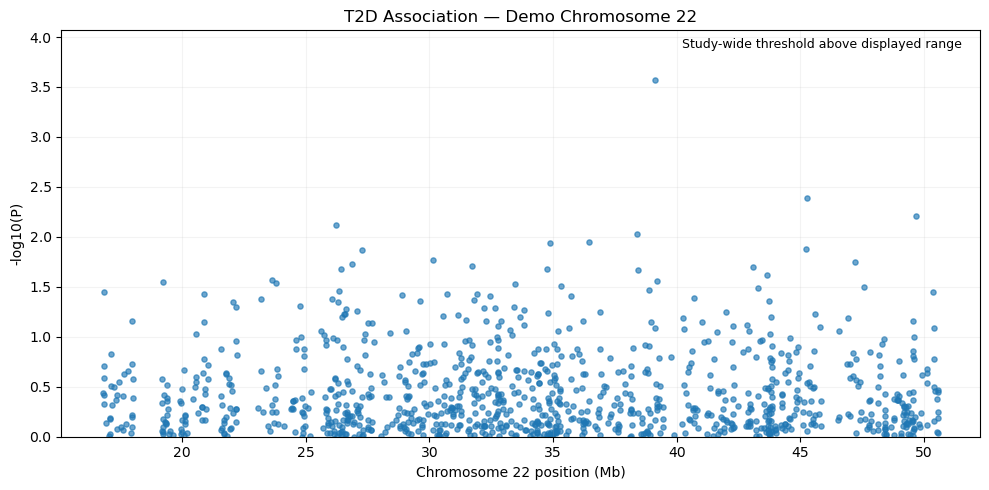

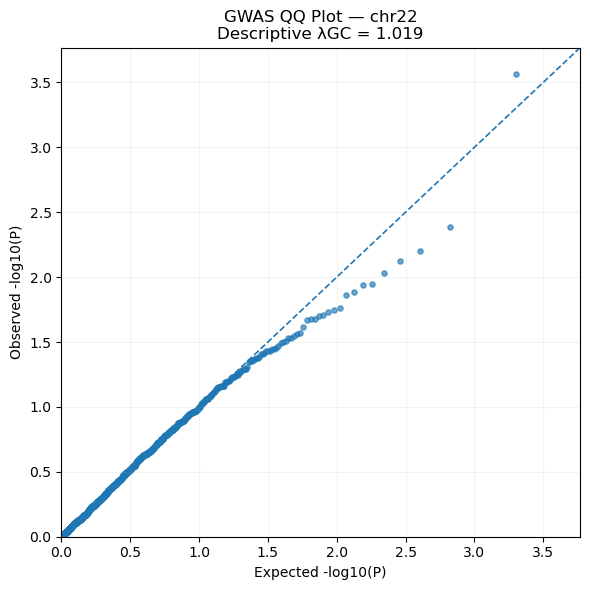

STEP 7 — GENETIC ANALYSIS COMPLETED

Genotype QC
Initial samples: 100
Final samples: 100
Initial SNPs: 1000
Final SNPs: 1000

T2D GWAS
Valid association tests: 1000
Minimum P: 0.000271099
Study-wide significant SNPs: 0

LD Clumping
Candidate index SNPs: 0
Clumped index SNPs: 0

QQ Plot
Descriptive lambda GC: 1.0195

Output directory:
Outputs/Step7_GWAS

Key output files:
QC_Summary.csv | Exists: True
GWAS_T2D.pheno | Exists: True
GWAS_T2D.covar | Exists: True
GWAS_T2D_chr22_TopSNPs.csv | Exists: True
GWAS_T2D_chr22_LeadVariants.csv | Exists: True
GWAS_T2D_chr22_Association.png | Exists: True
GWAS_T2D_chr22_QQ.png | Exists: True


In [8]:
# ============================================================
# 7. GWAS Visualization
# ============================================================

from scipy.stats import chi2


# ============================================================
# 7.1 Chromosome 22 Association Plot
# ============================================================

plot_df = assoc.copy()

plot_df["POS"] = pd.to_numeric(
    plot_df["POS"],
    errors="coerce"
)

plot_df = plot_df.loc[
    plot_df["POS"].notna()
    & np.isfinite(plot_df["NEG_LOG10_P"])
].copy()

assert not plot_df.empty


fig, ax = plt.subplots(
    figsize=(10, 5)
)

ax.scatter(
    plot_df["POS"] / 1e6,
    plot_df["NEG_LOG10_P"],
    s=14,
    alpha=0.65
)

THRESHOLD_Y = -np.log10(STUDY_WIDE_P)

OBSERVED_YMAX = float(
    plot_df["NEG_LOG10_P"].max()
)

PLOT_YMAX = max(
    3.0,
    OBSERVED_YMAX + 0.5
)

if THRESHOLD_Y <= PLOT_YMAX:

    ax.axhline(
        THRESHOLD_Y,
        linestyle="--",
        linewidth=1.2,
        label=(
            f"Study-wide P = {STUDY_WIDE_P:.1e}"
        )
    )

    ax.legend(frameon=False)

else:

    ax.text(
        0.98,
        0.98,
        (
            "Study-wide threshold "
            "above displayed range"
        ),
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9
    )


ax.set_xlabel(
    "Chromosome 22 position (Mb)"
)

ax.set_ylabel(
    "-log10(P)"
)

ax.set_title(
    "T2D Association — Demo Chromosome 22"
)

ax.set_ylim(
    0,
    PLOT_YMAX
)

ax.grid(alpha=0.15)

plt.tight_layout()

ASSOCIATION_FIGURE = (
    OUTPUT_DIR
    / "GWAS_T2D_chr22_Association.png"
)

fig.savefig(
    ASSOCIATION_FIGURE,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 7.2 QQ Plot Data
# ============================================================

p_values = assoc[
    "P"
].to_numpy(dtype=float)

p_values = p_values[
    np.isfinite(p_values)
    & (p_values > 0)
    & (p_values <= 1)
]

assert len(p_values) >= 2

p_sorted = np.sort(p_values)

n_tests = len(p_sorted)

expected_p = (
    np.arange(1, n_tests + 1) - 0.5
) / n_tests

expected_logp = (
    -np.log10(expected_p)
)

observed_logp = (
    -np.log10(p_sorted)
)


# ============================================================
# 7.3 Genomic Inflation Factor
# ============================================================

chi2_values = chi2.isf(
    p_values,
    df=1
)

LAMBDA_GC = float(
    np.median(chi2_values)
    / chi2.ppf(0.5, df=1)
)


# ============================================================
# 7.4 QQ Plot
# ============================================================

fig, ax = plt.subplots(
    figsize=(6, 6)
)

ax.scatter(
    expected_logp,
    observed_logp,
    s=14,
    alpha=0.65
)

MAX_AXIS = max(
    float(expected_logp.max()),
    float(observed_logp.max())
) + 0.2

ax.plot(
    [0, MAX_AXIS],
    [0, MAX_AXIS],
    linestyle="--",
    linewidth=1.2
)

ax.set_xlim(0, MAX_AXIS)
ax.set_ylim(0, MAX_AXIS)

ax.set_xlabel(
    "Expected -log10(P)"
)

ax.set_ylabel(
    "Observed -log10(P)"
)

ax.set_title(
    f"GWAS QQ Plot — chr22\n"
    f"Descriptive λGC = {LAMBDA_GC:.3f}"
)

ax.grid(alpha=0.15)

plt.tight_layout()

QQ_FIGURE = (
    OUTPUT_DIR
    / "GWAS_T2D_chr22_QQ.png"
)

fig.savefig(
    QQ_FIGURE,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 7.5 Final Summary
# ============================================================

N_FINAL, M_FINAL = count_bfile(
    QC_FINAL
)

print("=" * 65)
print("STEP 7 — GENETIC ANALYSIS COMPLETED")
print("=" * 65)

print("\nGenotype QC")
print("Initial samples:", N_INITIAL)
print("Final samples:", N_FINAL)

print("Initial SNPs:", M_INITIAL)
print("Final SNPs:", M_FINAL)

print("\nT2D GWAS")
print("Valid association tests:", len(assoc))
print("Minimum P:", float(assoc["P"].min()))

print(
    "Study-wide significant SNPs:",
    int(assoc["Study_Wide_Significant"].sum())
)

print("\nLD Clumping")
print("Candidate index SNPs:", N_CLUMP_CANDIDATES)
print("Clumped index SNPs:", len(lead_variants))

print("\nQQ Plot")
print("Descriptive lambda GC:", round(LAMBDA_GC, 4))

print("\nOutput directory:")
print(OUTPUT_DIR.relative_to(PROJECT_ROOT))

print("\nKey output files:")

for filename in [
    "QC_Summary.csv",
    "GWAS_T2D.pheno",
    "GWAS_T2D.covar",
    "GWAS_T2D_chr22_TopSNPs.csv",
    "GWAS_T2D_chr22_LeadVariants.csv",
    "GWAS_T2D_chr22_Association.png",
    "GWAS_T2D_chr22_QQ.png",
]:

    file = OUTPUT_DIR / filename

    print(
        filename,
        "| Exists:",
        file.is_file()
    )